# Licence, contract, split and test: how a case is built from a licensed source file

**Question:** When a public file enters the pipeline, what does each of its four stages guarantee (a licence and a hash, a contract, a leakage-safe split, a test row), and with how few defaults does the last guarantee stop being worth anything?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- read a source in the registry and say which cases may read it and whether a document derived from it may be published;
- read the hash the licence manifest pins for a licensed file, the rule by which the stage refuses a file that differs from it, and what the stage says when the file is absent;
- say what contract 1 accepted, rejected or ignored on the committed 50-applicant German sample, and read the committed declarations of its eight families;
- cut a file with the stratified split and show, against a plain random split, why the holdout keeps the default rate;
- run the battery of the evaluation stage and read one test row field by field against the documented `test-result` contract;
- follow the licence lineage from the registry to the provenance block of a committed document, and say what the models envelope shares between cases;
- find the number of defaults below which the case stops being worth running, and apply the same checks to a file of your own.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 pandas==3.0.6 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. This notebook also imports the four stages of the product's pipeline (`pipeline.stages.ingest`, `split`, `evaluate` and `export`) and a few of its readers. The pipeline is plain scripts and not a package, so the next cell puts `data-pipeline/` on the import path and imports them from there: one reader for the pipeline, the tests and these notebooks, never a copy. The notebook reads committed files only: it never reads the data root and never writes a file. The cell prints the version of every package.

In [1]:
# Put the pipeline on the import path, import its stages and the engine, and print the versions
import hashlib
import importlib.metadata as md
import inspect
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.validation import calibration as cal, discrimination as disc
from scipy.stats import norm
from sklearn.model_selection import train_test_split

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import c01_features as feat
from pipeline.core import lineage
from pipeline.io import fetch as fetching, readers
from pipeline.io import sources as registry
from pipeline.io.contract import validate
from pipeline.stages import evaluate, export, ingest, split


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


for name in ("riskvalidation", "numpy", "pandas", "scikit-learn", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2


## Data

The case we follow is C01 (retail credit PD) and the file is its second source, the German Credit data.

- **Owner and licence:** Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data. Licence class `mirror-allowed` (CC BY 4.0, https://creativecommons.org/licenses/by/4.0/).
- **Content:** 1,000 loan applicants, 20 attributes and a good or bad outcome, 300 of them bad. It is the small-sample twin of the Taiwan card file that case C01 also reads.
- **File behind the case, not read here:** `statlog+german+credit+data.zip` (29,607 bytes), kept under `raw/uci-german/` in the data root. It is not in the repository and this notebook never reads it. A reader who holds the licence fetches it and bakes the case with the two commands below, which the notebook shows and never runs. What the notebook reads instead is committed: the manifest entry of the file, the 50-applicant sample of the committed German twin, its split counts and its battery rows.

  ```bash
  python data-pipeline/fetch.py uci-german --data-root <your data root>
  python data-pipeline/run.py C01 --output <a sandbox folder>
  ```

- **Why not the Taiwan file:** it is a spreadsheet that needs the `xlrd` reader, which the notebook environment does not pin. The German file is plain text and goes through the same four stages.
- **Committed documents read** (paths from the repository root): `data-pipeline/config/sources.json`, `data-pipeline/config/licences.json`, `data/sources/manifest.json`, `data/derived/contract/index.json`, `data/derived/contract/scored_sample.json`, `docs/contracts/examples/common.test-result.json` with its schema, `data/derived/C01/german-twin.json`, `data/derived/C01/models-german.json`, `data/derived/C22/models-generators.json` and the schema of the models envelope.

## Method

A case is a function from a source file to a document, and the pipeline cuts that function into four stages, each ending in a guarantee that a later reader can check. `ingest` lets the registry, the pinned hash and contract 1 decide what may enter. `split` cuts the records so that nothing leaks from the holdout into the fit. `evaluate` runs the engine's tests, under a policy, on the holdout. `export` validates the document against its schema and writes it with its lineage. The notebook walks the four on the committed German case, running each stage function on a committed sample, reading at each stage the committed document that governs it, and finishes by asking where the chain stops being informative.

### Step 1: the registry decides whether a case may read a source

`data-pipeline/config/sources.json` is the source registry (contract `source-registry`): every data source the product knows, with the publisher's own words on its licence, its redistribution class and the cases that may read it. `registry.load()` reads and checks it, and `assert_case_inputs` asks the question the pipeline must never get wrong: may this case read this source? The next cell loads the registry and counts its sources by class.

sources in the registry: 58 | readable by a case: 41


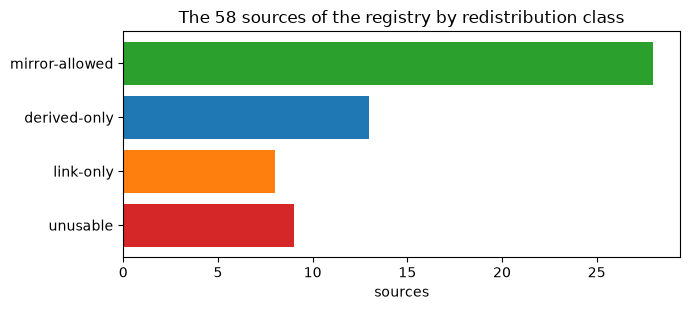

In [2]:
# Load and check the source registry, then count its sources by redistribution class
sources = registry.load()
by_class = pd.Series(Counter(s.klass for s in sources.values()), name="sources").reindex(registry.CLASSES)
print("sources in the registry:", len(sources), "| readable by a case:", sum(s.readable for s in sources.values()))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(by_class.index, by_class.values, color=["tab:green", "tab:blue", "tab:orange", "tab:red"])
ax.invert_yaxis()
ax.set_xlabel("sources")
ax.set_title(f"The {len(sources)} sources of the registry by redistribution class")
fig.tight_layout()
plt.show()

The registry holds 58 sources. Twenty-eight are `mirror-allowed`, whose raw rows may be committed to the repository. Thirteen are `derived-only`, which a case may read and whose derived results it may publish while the rows stay out of the repository. Eight are `link-only` and nine `unusable`: a case may link them and never read them. Forty-one of the 58, the first two bars, are therefore readable by a case. The figure gives the licence situation of the product's inputs at a glance. It does not show what each class forbids in detail, which is written in the `licence` field of every entry, and it says nothing about whether a source is still online.

In [3]:
# Ask the registry three questions a case must never get wrong: a listed source, another case's source, a link-only one
link_only = next(s.id for s in sources.values() if s.klass == "link-only")
questions = [("C01", "uci-german"), ("C05", "uci-german"), ("C01", link_only)]
answers = []
for case, source in questions:
    try:
        registry.assert_case_inputs(case, [source], registry=sources)
        answers.append({"case": case, "source": source, "answer": "may read it"})
    except registry.LicenceError as refusal:
        answers.append({"case": case, "source": source, "answer": str(refusal)})
pd.DataFrame(answers)

,case,source,answer
0,C01,uci-german,may read it
1,C05,uci-german,C05: uci-german does not list C05 among its ca...
2,C01,kaggle-gmsc,C01: kaggle-gmsc is link-only; it may be linke...


The registry answers three questions in three ways. Case C01 may read `uci-german`, because the source lists C01 among its cases. Case C05 may not: the reply says that `uci-german` does not list C05 and that the registry must be updated first, so a new use of a source is a registry change a reviewer sees before any data moves. And C01 may not read `kaggle-gmsc`, a link-only source, which may be linked and never read. The table shows the wording of the refusals, which is what a developer meets in a failing log. It does not show who decides which cases a source lists; that is whoever adds the case and edits the registry in the same change.

### Step 2: the licence manifest pins the bytes

The registry says whether a source may be read; the licence manifest `data/sources/manifest.json` says which bytes were read (contract `licence-manifest`). Each entry copies the publisher's licence words, the class and the attribution from the registry at the time of the download, and adds the list of files with their name, URL, size, retrieval date and SHA-256 hash. Only `data-pipeline/fetch.py` writes it. The next cell prints the entry of `uci-german`, field by field.

In [4]:
# One entry of the licence manifest, field by field: the publisher's words, the class and the pinned file
manifest = fetching.load_manifest()
entry = manifest["sources"]["uci-german"]
pinned = entry["files"][0]
fields = {key: entry[key] for key in ("publisher", "class", "access", "licence", "attribution")}
fields.update({f"file {key}": pinned[key] for key in ("name", "bytes", "retrieved")})
fields["file sha256"] = pinned["sha256"][:16] + "..."
pd.Series(fields, name="uci-german").to_frame()

,uci-german
publisher,UCI Machine Learning Repository / H. Hofmann
class,mirror-allowed
access,http
licence,This dataset is licensed under a Creative Comm...
attribution,"Hofmann, H. (1994). Statlog (German Credit Dat..."
file name,statlog+german+credit+data.zip
file bytes,29607
file retrieved,2026-10-05
file sha256,e12d9d5def6845c0...


The entry gives the publisher (UCI and H. Hofmann), the class `mirror-allowed`, the access method `http`, the licence sentence, the attribution to cite, and one file: `statlog+german+credit+data.zip`, 29,607 bytes, retrieved on 2026-10-05, with a SHA-256 hash that begins `e12d9d5def6845c0`. The nine rows are the whole provenance of the raw input. They do not give the content of the file, and that is what the stage compares. It accepts a file $f$ only if its hash equals the one the manifest pins,

$$\mathrm{accept}(f) \iff \mathrm{SHA\text{-}256}(f) = h_{\mathrm{pin}}$$

where $f$ is the byte content of the file and $h_{\mathrm{pin}}$ the 64-digit hash of the manifest (NIST FIPS 180-4, https://doi.org/10.6028/NIST.FIPS.180-4). The next cell hashes the file on disk and sets the result beside the pin. Then it pins a wrong value in a copy of the manifest and lets the stage read the same, unchanged file again.

In [5]:
# Hash a committed text, show the rule the stage applies to a fetched one, and read what the stage says without the
# licensed file
digest = hashlib.sha256(entry["licence"].encode("utf-8")).hexdigest()
print(
    "sha256 of the licence sentence of the manifest entry:", digest[:16], "| pin of the German file:",
    pinned["sha256"][:16]
)
print(
    "a pin is", len(pinned["sha256"]), "hexadecimal characters, the hash of", len(bytes.fromhex(pinned["sha256"])),
    "bytes"
)
rule = [line.strip() for line in inspect.getsource(ingest.raw_file).splitlines()
    if "digest" in line and "pinned[name]" in line]
print("the stage's rule:", rule)
try:
    ingest.raw_file("uci-german", pinned["name"], ROOT / "data" / "absent-data-root")
except ingest.IngestError as refusal:
    print("without the licensed file the stage says:", str(refusal).split(" is missing: ")[1])

sha256 of the licence sentence of the manifest entry: e20a8d147234ab62 | pin of the German file: e12d9d5def6845c0
a pin is 64 hexadecimal characters, the hash of 32 bytes
the stage's rule: ['if digest != pinned[name]:']
without the licensed file the stage says: fetch it with data-pipeline/fetch.py uci-german --data-root <root>


The pin of the German file begins `e12d9d5def6845c0`: a pin is 64 hexadecimal characters, the SHA-256 digest of 32 bytes (NIST, 2015). The cell computes the same digest on a committed text, the licence sentence of the manifest entry, only to show the computation. The stage's rule is one line, `if digest != pinned[name]`: it hashes the fetched file and refuses it when the digest is not the pinned one. Without the licensed file, which is the situation of a clone of this repository, the stage does not guess: it says to fetch it with `data-pipeline/fetch.py uci-german --data-root <root>`. The guard is blunt on purpose. If the publisher replaced the file, or a download was cut short, the documents derived from it would no longer derive from what the manifest records, and no later stage could notice. A reader who holds the licence runs the commands of the Data section; this notebook never does. The cell shows the rule, the pin and the message, and it does not show a refusal of a wrong hash, which needs the file. It does not show that the pinned file is the one the publisher meant either; only the URL and the retrieval date in the manifest can say that.

### Step 3: contract 1 decides which records enter

After the hash the stage passes the publisher's records through contract 1, which parses every value by its declared kind and accepts, rejects, flags or excludes each record (notebook 04 showed it on a sample of your own). Its declarations are committed. `data/derived/contract/index.json` lists the eight families (contract `contract-index`), and one document per family declares its fields, its rules and its parameters (contract `contract-family`). The next cell reads the index, opens each family and counts what it declares.

In [6]:
# The committed declarations of contract 1: the index of its eight families and what each family declares
index = read_json("data/derived/contract/index.json")
declared = []
for item in index["families"]:
    family = read_json(f"data/derived/contract/{item['path']}")
    declared.append(
        {"family": item["family"], "fields": len(family["fields"]), "rules": len(family["rules"]),
         "open fields": family["open_fields"], "used by": family["used_by"]["en"][:48]}
    )
pd.DataFrame(declared)

,family,fields,rules,open fields,used by
0,scored_sample,9,2,True,Every PD and ML case: one row per obligor or acc
1,loan_panel,14,6,False,"Lifetime PD, IFRS 9 staging and ECL, LGD and EAD"
2,rating_history,3,3,False,"Transition matrices, default rates by grade and"
3,market_series,4,2,False,"VaR and ES, backtests and stress windows: one ro"
4,curve,4,2,False,"IRRBB, rates VaR, exposure simulation: one row p"
5,balance_sheet,12,1,False,"IRRBB and liquidity: one row per item, currency"
6,loss_events,6,3,False,Operational risk LDA and SMA: one row per loss e
7,macro_path,6,2,False,"Stress testing, IFRS 9 scenarios, satellites: on"


There are eight families, one for each kind of input the cases bring: the scored sample (9 fields and 2 rules, with open fields because each case adds its own features), the loan panel (14 fields, 6 rules), the rating history (3 and 3), the market series (4 and 2), the curve (4 and 2), the balance sheet (12 and 1), the loss events (6 and 3) and the macro path (6 and 2). The case we follow uses the first. The table shows how much each family asks of a source: a rating history needs three fields and a loan panel fourteen. It does not show the rules themselves; each family document states every rule with its scope, its policy (reject, flag or exclude) and its statement in English and Spanish. The next cell runs contract 1, the check inside the ingest stage, on the 50 applicants of the committed German sample with the family `scored_sample` and the case's own extra fields.

In [7]:
# Run contract 1, the check inside the ingest stage, on the 50 applicants of the committed German sample
twin = read_json("data/derived/C01/german-twin.json")
sample = twin["outputs"]["sample"]
records = [
    {"id": ident, "observation_date": readers.GERMAN_OBSERVATION_DATE, "target": target,
     **{name: values[k] for name, values in sample["inputs"].items()}}
    for k, (ident, target) in enumerate(zip(sample["ids"], sample["targets"]))
]
report = validate("scored_sample", records, extra_fields=feat.GERMAN_FIELDS)
frame = pd.DataFrame(report.accepted)
print("contract 1:", report.counts())
print("ignored columns:", report.ignored_columns)
print("applicants:", len(frame), "| defaults:", int(frame["target"].sum()))
print("default rate:", round(float(frame["target"].mean()), 3))

contract 1: {'input': 50, 'accepted': 50, 'rejected': 0, 'flagged': 0, 'excluded': 0}
ignored columns: []
applicants: 50 | defaults: 12
default rate: 0.24


Contract 1 returns 50 accepted records out of 50 read, with none rejected, flagged or excluded, so the committed German sample is a clean input to the contract. No column is ignored, because the sample carries only the model inputs; ignored columns are what the report lists when a source brings more than the case declares, for instance the protected attributes, which the reader keeps for the fairness tests only. The frame holds 50 applicants and 12 defaults, a default rate of 0.24, below the 0.3 of the whole file that the next step uses, because 50 applicants are a slice. This is the object every later stage takes: a table of accepted records in input order and a report of what happened to the rest. A report with rejections is the first thing to read in a new case, because everything below is computed from the accepted rows only.

### Step 4: a split that cannot leak

The second stage cuts the accepted records into three disjoint parts: a training part where models are fitted, a calibration part where anything fitted on top of a model (a score map, the initial AUC) is fitted, and a locked holdout that is opened once. `split.stratified_split` takes the labels and a seed, sets aside the holdout fraction $h$ (30 percent by default) and then the calibration fraction of the rest (20 percent), stratifying each time on the default flag, and adds repeated stratified folds inside the training part for every choice a method makes. The number of defaults in the holdout is then fixed by construction,

$$d_h = \mathrm{round}\,(h\,D)$$

where $D$ is the number of defaults of the file, so the holdout keeps the default rate of the file up to one record. The partition is a pure function of the labels and the seed (scikit-learn, https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html). The licensed file is not read here, and the split depends on the labels alone, so the next cell rebuilds a label vector with the counts of the committed models document (1,000 applicants and 300 defaults, placed at random positions with a fixed seed), cuts it with seed 42, lists what each part holds and compares the sizes and default counts with the committed split.

In [8]:
# Rebuild the labels of the file from the committed split counts, cut them with the stage's stratified split and
# list what each part holds
committed_split = read_json("data/derived/C01/models-german.json")["fit"]["split"]
names = ("train", "calibration", "holdout")
n_file = sum(committed_split[name]["n"] for name in names)
d_file = sum(committed_split[name]["defaults"] for name in names)
y_all = np.zeros(n_file, dtype=int)
y_all[np.random.default_rng(0).choice(n_file, size=d_file, replace=False)] = 1
parts = split.stratified_split(y_all, seed=42)
summary = parts.summary(y_all)
table = pd.DataFrame({name: summary[name] for name in names}).T
table[["n", "defaults"]] = table[["n", "defaults"]].astype(int)
print("applicants:", n_file, "| defaults:", d_file, "| default rate:", round(float(y_all.mean()), 3))
print("parts disjoint:", parts.disjoint(), "| folds inside the training part:", len(parts.folds))
print("same sizes and defaults as the committed split:", all(
    summary[name][key] == committed_split[name][key] for name in names for key in ("n", "defaults")))
needed = cal.critical_default_count(len(parts.holdout), float(y_all.mean()), q=0.95)
print("defaults a 95% level test needs in the holdout before it objects:", needed)
print("defaults expected:", summary["holdout"]["defaults"])
table

applicants: 1000 | defaults: 300 | default rate: 0.3
parts disjoint: True | folds inside the training part: 10
same sizes and defaults as the committed split: True
defaults a 95% level test needs in the holdout before it objects: 104
defaults expected: 90


,n,defaults,default_rate
train,560,168,0.3
calibration,140,42,0.3
holdout,300,90,0.3


The partition has 560 training, 140 calibration and 300 holdout records, with 168, 42 and 90 defaults: a default rate of exactly 0.3 in each part, the rate of the file. The sizes and default counts equal those of the committed split (`True`), the parts are disjoint (`True`) and the training part carries 10 folds, 5 for each of 2 repetitions. The table is what a reviewer asks of a split before looking at any model: that nothing is shared between the parts and that each has enough defaults to test on. Ninety defaults in the holdout is comfortable, and the engine says how comfortable: its `critical_default_count` puts the point at which a level test at the 95 percent level objects at 104 defaults in a holdout of 300 records with a default rate of 0.3, an excess of 16 percent over the 90 expected. The sweep at the end of the notebook shows how that count shrinks. The table does not show that the features are free of leakage, for instance a column computed after the default date; that is a property of the reader and of the contract, not of the split.

Why stratify at all? A plain random holdout of $n_h$ records out of $n$ draws its defaults without replacement, so the default rate of the holdout has the standard deviation of a hypergeometric draw,

$$\mathrm{sd}(\hat\pi_h) = \sqrt{\frac{\bar y\,(1-\bar y)}{n_h}\left(1 - \frac{n_h}{n}\right)}$$

where $\bar y$ is the default rate of the file and the bracket is the finite-population correction (https://en.wikipedia.org/wiki/Hypergeometric_distribution). A model scored on a holdout that happens to be rich in defaults looks worse for no reason of its own. The next cell repeats the split over 300 seeds for five holdout fractions, once with the stage's stratified split and once with a plain random one, and prints the five standard deviations of each.

In [9]:
# The holdout default rate over 300 seeds, with the stage's stratified split and with a plain random split
fractions = [0.05, 0.1, 0.2, 0.3, 0.5]
sd_stratified, sd_random, at_ten = [], [], {}
for fraction in fractions:
    stratified, plain = [], []
    for seed in range(300):
        held = split.stratified_split(y_all, seed=seed, holdout=fraction).holdout
        stratified.append(y_all[held].mean())
        _, held = train_test_split(np.arange(len(y_all)), test_size=fraction, random_state=seed)
        plain.append(y_all[held].mean())
    sd_stratified.append(np.std(stratified))
    sd_random.append(np.std(plain))
    if fraction == 0.1:
        at_ten = {"stratified": stratified, "random": plain}
print("standard deviation of the holdout rate, stratified:", np.round(sd_stratified, 4))
print("standard deviation of the holdout rate, random:    ", np.round(sd_random, 4))

standard deviation of the holdout rate, stratified: [0. 0. 0. 0. 0.]
standard deviation of the holdout rate, random:     [0.0624 0.0441 0.0304 0.0221 0.0139]


The first line is zero at every fraction, as the construction says, and the second falls as the holdout grows. The next cell draws the 10 percent case as two histograms and the five standard deviations of the random split against the formula above, which it prints.

formula for the random split: [0.0632 0.0435 0.029  0.0221 0.0145]


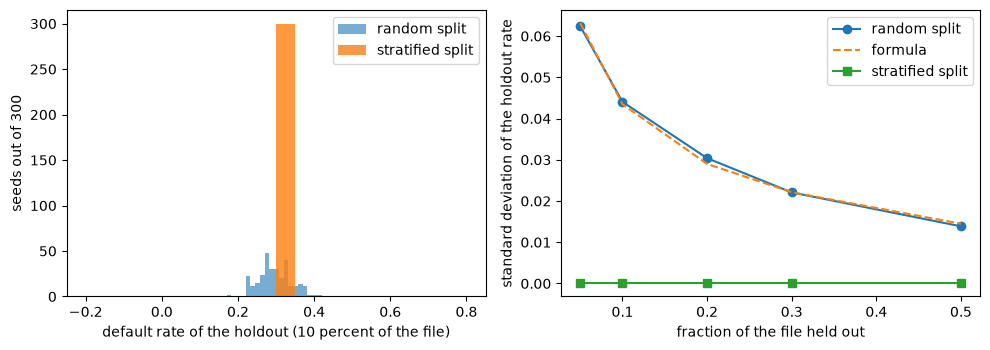

In [10]:
# Draw the two spreads at a holdout of 10 percent, and the spread of the random split against the formula, by fraction
rate = y_all.mean()
size = np.array(fractions) * len(y_all)
formula = np.sqrt(rate * (1 - rate) / size * (1 - size / len(y_all)))
print("formula for the random split:", np.round(formula, 4))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.hist(at_ten["random"], bins=20, alpha=0.6, label="random split")
left.hist(at_ten["stratified"], bins=20, alpha=0.8, label="stratified split")
left.set_xlabel("default rate of the holdout (10 percent of the file)")
left.set_ylabel("seeds out of 300")
left.legend()
right.plot(fractions, sd_random, marker="o", label="random split")
right.plot(fractions, formula, linestyle="--", label="formula")
right.plot(fractions, sd_stratified, marker="s", label="stratified split")
right.set_xlabel("fraction of the file held out")
right.set_ylabel("standard deviation of the holdout rate")
right.legend()
fig.tight_layout()
plt.show()

On the left, with 10 percent of the file held out, the random split spreads the holdout default rate over a bell of standard deviation 0.0441 around the file's 0.3, and the stratified split is a single spike at 0.3. On the right the standard deviation of the random split falls from 0.0624 with 5 percent held out to 0.0139 with 50 percent, and it follows the formula (0.0632, 0.0435, 0.029, 0.0221 and 0.0145) to within 5 percent. The stratified split sits at zero at every fraction. The figure shows that stratification removes a source of noise an evaluator would otherwise attribute to the model, and that the noise of a plain split is largest exactly where holdouts are small. It does not show that stratifying is free: a stratified holdout is no longer a random draw of the label, which is the right design for evaluating a model and the wrong one for estimating the base rate of a new population.

### Step 5: the evaluation stage runs the engine's tests

`evaluate.battery` is the third stage and it adds no statistic of its own. Every test is the engine's, run under its versioned policy; what the stage decides is the design: which sample each test reads, which reference each stability test compares against and in which order the rows come. It takes the PDs and outcomes of the holdout and, as references, the training PDs (for the PSI), the calibration PDs and outcomes (for the AUC against the initial validation and the grade concentration) and, when there is a champion, its PDs for the paired AUC test. The notebook needs no model of its own: the committed German twin holds the battery rows that the stage produced for the scorecard rung on its 300 holdout applicants, and a sample of 50 applicants with the scorecard's PD. The next cell reads both. The stage does not care where the PDs come from.

In [11]:
# The inputs of the evaluation stage that the committed documents hold: the battery rows of the scorecard and its
# 50-applicant sample
policy = default_policy()
rows = [row for row in twin["tests"] if row["model_id"] == "P1-scorecard"]
pd_sample, y_sample = np.array(sample["scorecard_pd"]), np.array(sample["targets"])
print(
    "battery rows of the scorecard in the committed document:", len(rows), "| holdout records behind them:",
    rows[0]["n"]
)
print(
    "applicants in the sample:", len(y_sample), "| defaults:", int(y_sample.sum()), "| mean scorecard PD:",
    round(float(pd_sample.mean()), 4)
)
print("engine that baked the document:", twin["provenance"]["riskvalidation_version"])

battery rows of the scorecard in the committed document: 24 | holdout records behind them: 300
applicants in the sample: 50 | defaults: 12 | mean scorecard PD: 0.2601
engine that baked the document: 1.1.0


The cell reads the 24 battery rows of the scorecard rung, computed on 300 holdout applicants, and the sample of 50 applicants with 12 defaults and a mean PD of 0.2601. The next cell counts the committed rows by light, lists the tests, the p-values of the portfolio rows and the rows that are not green, and then calls the battery on the sample: the first 25 applicants are the reference of the PSI and the last 25 are evaluated. With no calibration part, the AUC against the initial validation and the grade concentration are not run.

In [12]:
# Read the committed battery rows, then run the stage's battery on the sample and compare it with a direct engine call
print("rows returned:", len(rows), "| by light:", dict(Counter(row["light"] for row in rows)))
print("tests run:", sorted({row["test_id"] for row in rows}))
portfolio = {row["test_id"]: row["p_value"] for row in rows if row["segment"] == "portfolio"}
print("portfolio p-values:", {k: float(f"{v:.3g}") for k, v in portfolio.items() if v is not None})
amber = [(r["test_id"], r["segment"], round(r["p_value"], 4)) for r in rows if r["light"] in ("amber", "red")]
print("amber or red rows:", amber)
half = len(y_sample) // 2
sample_rows = evaluate.battery(
    "scorecard-sample", pd_sample[half:], y_sample[half:], pd_train=pd_sample[:half], pd_cal=None, y_cal=None,
    champion_pd=None, policy=policy,
)
print(
    "rows of the stage on the last", len(y_sample) - half, "applicants:", len(sample_rows), "| tests run:",
    len({r["test_id"] for r in sample_rows})
)
direct = disc.disc_auc(pd_sample[half:], y_sample[half:], policy=policy)
stage_auc = next(row["metric"] for row in sample_rows if row["test_id"] == "disc.auc")
print("AUC in the stage row:", round(stage_auc, 6), "| AUC from a direct engine call:", round(direct.metric, 6))

rows returned: 24 | by light: {'not_evaluated': 4, 'green': 20}
tests run: ['disc.auc', 'disc.auc_vs_initial', 'disc.ks', 'pd.binomial', 'pd.binomial_vasicek', 'pd.brier', 'pd.chi2_grades', 'pd.ece', 'pd.hosmer_lemeshow', 'pd.jeffreys', 'pd.spiegelhalter', 'rating.hhi', 'stability.psi']
portfolio p-values: {'disc.auc_vs_initial': 0.162, 'disc.ks': 1.72e-12, 'pd.jeffreys': 0.421, 'pd.binomial': 0.445, 'pd.binomial_vasicek': 0.461, 'pd.chi2_grades': 0.973, 'pd.hosmer_lemeshow': 0.876, 'pd.spiegelhalter': 0.407, 'stability.psi': 0.42, 'rating.hhi': 0.565}
amber or red rows: []
rows of the stage on the last 25 applicants: 20 | tests run: 11
AUC in the stage row: 0.674603 | AUC from a direct engine call: 0.674603


The committed document holds 24 rows from 13 tests: 20 green and 4 not evaluated, none amber or red. The tests are the AUC, the AUC against the initial validation, the Kolmogorov-Smirnov statistic, the Jeffreys test (one row per occupied grade, 11, and one for the portfolio, Brown, Cai and DasGupta 2001), the binomial and Vasicek-adjusted binomial tests, the chi-square over grades, Hosmer-Lemeshow, Spiegelhalter, the Brier score, the expected calibration error, the PSI and the grade concentration. The four rows without a light are the AUC, the KS statistic, the Brier score and the calibration error, which the default policy leaves without cut points (notebooks 02 and 03). The portfolio p-values of the coloured tests are far from the cut points, the smallest being 0.162 for the AUC against the initial validation; the 1.72e-12 of the Kolmogorov-Smirnov row belongs to a test without cut points. The stage run on the sample returns 20 rows from 11 tests, the 13 minus the two that need a calibration part, and shows what the stage adds to the engine, which is nothing statistical: the AUC in the stage row, 0.674603, equals the AUC of a direct engine call on the same arrays, 0.674603. That AUC, from 25 applicants, is far from the 0.7883 of the committed document on 300, a gap whose size is the subject of the last section.

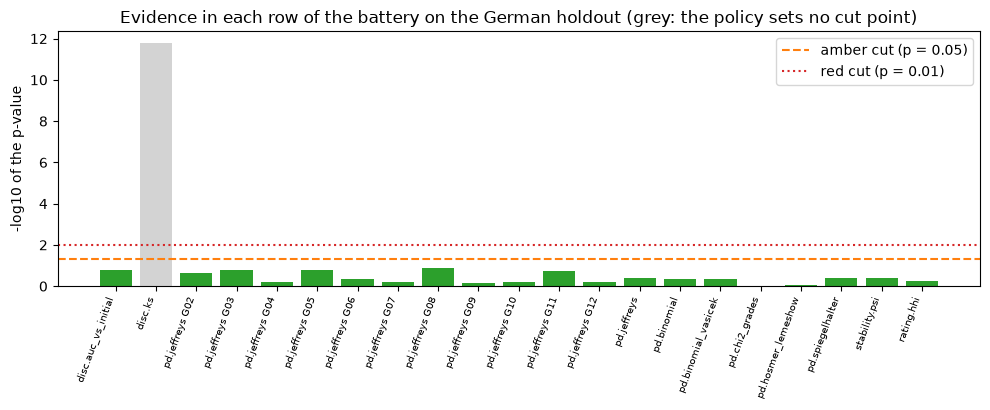

In [13]:
# Draw every row that has a p-value as minus the base-10 logarithm of it, coloured by the light the policy gave
shades = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red", "not_evaluated": "lightgray"}
shown = [row for row in rows if row["p_value"] is not None]
names = [row["test_id"] + ("" if row["segment"] == "portfolio" else " " + row["segment"]) for row in shown]
heights = [-np.log10(max(row["p_value"], 1e-300)) for row in shown]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(range(len(shown)), heights, color=[shades[row["light"]] for row in shown])
ax.axhline(-np.log10(0.05), color="tab:orange", linestyle="--", label="amber cut (p = 0.05)")
ax.axhline(-np.log10(0.01), color="tab:red", linestyle=":", label="red cut (p = 0.01)")
ax.set_xticks(range(len(shown)))
ax.set_xticklabels(names, rotation=70, ha="right", fontsize=7)
ax.set_ylabel("-log10 of the p-value")
ax.set_title("Evidence in each row of the battery on the German holdout (grey: the policy sets no cut point)")
ax.legend()
fig.tight_layout()
plt.show()

Each bar is minus the base-10 logarithm of the p-value of one row, so a taller bar is stronger evidence against the PDs, and its colour is the light the policy gave. The 21 rows that have a p-value are drawn. The portfolio rows are short and green: level and fit are not rejected on the holdout. No bar crosses the amber line; the lowest coloured bar is the Jeffreys test of grade G08, with a p-value of 0.1317, among 12 Jeffreys rows. The tallest bar is grey: the Kolmogorov-Smirnov statistic has a p-value of 1.72e-12, and the policy colours nothing for it, so the largest bar of the figure carries no light. The figure shows that no coloured test rejects this scorecard on 300 applicants with 90 defaults. It does not show that the scorecard is right: how much a test can see at that size is what the last section measures.

### Step 6: a test row is the contract `test-result`

Every row the battery returns has the same shape, defined by the schema `docs/contracts/schemas/common/test-result.schema.json` (contract `test-result`) and illustrated by a documented example. The schema requires 18 keys: the test and the model it was run on, the segment, the statistic, the p-value and the metric, the null hypothesis and its alternative, the policy that coloured the row with its two cut points and the light, the sample size and the number of events, a hash of the inputs, the reference that defines the test, free notes and the extras of that test. The next cell sets the documented example beside the Jeffreys test of our holdout, called on the engine directly with the counts of the holdout (the battery makes the same call), with long values cut at 46 characters.

In [14]:
# The documented example of a test row beside one row of our battery: the same keys and, for each, a value
example = read_json("docs/contracts/examples/common.test-result.json")
schema = read_json("docs/contracts/schemas/common/test-result.schema.json")
ours = next(r for r in rows if r["test_id"] == "pd.jeffreys" and r["segment"] == "portfolio")
both = pd.DataFrame({"documented example": example, "our portfolio row": ours}).map(lambda value: str(value)[:46])
print("keys the schema requires:", len(schema["required"]), "| keys of our row:", len(ours))
print(
    "our row: n", ours["n"], "| defaults", ours["n_events"], "| p-value", round(ours["p_value"], 4), "| light",
    ours["light"]
)
both

keys the schema requires: 18 | keys of our row: 18
our row: n 300 | defaults 90 | p-value 0.4206 | light green


,documented example,our portfolio row
test_id,pd.jeffreys,pd.jeffreys
model_id,E0-expert,P1-scorecard
segment,A,portfolio
statistic,0.0,0.3
p_value,0.193755529,0.420596273
metric,None,None
h0,the PD applied at the start of the period is g,the PD applied at the start of the period is g
alternative,the true PD exceeds the PD applied (underestim,the true PD exceeds the PD applied (underestim
policy_version,riskvalidation-default 2026.10.1,riskvalidation-default 2026.10.1
alpha_amber,0.05,0.05


Both columns have the same 18 keys. The example is an expert PD tested on 100 obligors with no default, a p-value of 0.1938 and a green light; ours is the scorecard on the 300 holdout applicants with 90 defaults, a p-value of 0.4206, also green. What the shape buys is that nothing is lost between the engine and the reader. The row carries its null hypothesis (`h0`) and the direction of the alternative, the policy label and the two cut points that coloured it, so the light can be read again under another policy as in notebook 03, and `inputs_hash`, a fingerprint of the arguments, so two rows can be told to come from the same inputs. `extras` is the one free key: for the Jeffreys test it holds the applied PD and the posterior quantiles. The table does not show how a row is checked on its way into a document; that is the schema validation of the export stage.

### Step 7: export writes a document that carries its lineage

The last stage turns rows and arrays into a committed document. `export.write_artifact` validates the document against its schema before a single byte is written, so an invalid document is never written; it compacts every float to nine significant digits so the committed files stay inside the size budget; it records the measured size and lane; and it writes the `provenance` block built from the registry and the manifest. The notebook writes nothing: it reads what the stage would write. The next cell compacts one of our rows and shows what the rounding does to it.

In [15]:
# The export stage rounds every float to nine significant digits before a document is written: one row, before and after
committed_row = next(r for r in rows if r["test_id"] == "pd.binomial" and r["segment"] == "portfolio")
row = cal.pd_binomial(
    committed_row["n"], committed_row["n_events"], committed_row["extras"]["expected_defaults"] / committed_row["n"],
    policy=policy, model_id="P1-scorecard", segment="portfolio",
).to_dict()
rounded = export.compact(row)
print("p-value before:", repr(row["p_value"]))
print("p-value after: ", repr(rounded["p_value"]))
print("bytes of the row as JSON:", len(json.dumps(row)), "->", len(json.dumps(rounded)), "| digits kept:", export.SIG)
cut = policy.threshold(row["test_id"])
print("light stored:", row["light"], "| light of the rounded p-value:", cut.classify(rounded["p_value"]).value)

p-value before: 0.44541243934705604
p-value after:  0.445412439
bytes of the row as JSON: 903 -> 895 | digits kept: 9
light stored: green | light of the rounded p-value: green


The p-value of the binomial test, 0.44541243934705604 in memory, is 0.445412439 after compaction: nine significant digits, enough for every statistic the views show, and the JSON of the row shrinks from 903 to 895 bytes. The compaction is a rounding that cannot change a light, because the light was assigned from the unrounded value before the export; the cell checks it by classifying the rounded p-value with the policy's threshold, which gives green, the light stored. It does not apply to the inputs of additive scores, which the stage leaves exact through its `exact` argument, since the web recomputes them to a tolerance of 1e-9. The next cell builds the lineage that the stage would write for the German twin, reads the committed document and sets the two beside each other, and then compares the keys of two committed models documents with the envelope.

In [16]:
# The lineage the export stage writes for the German twin, built from the registry and the manifest, and its envelope
chain = lineage.build("C01", sources=["uci-german"], truth_status="real-outcomes", seed=42, code_version="1.00.000")
twin = read_json("data/derived/C01/german-twin.json")
print("built here   :", chain.provenance()["inputs"][0]["files"][0]["sha256"][:16], chain.classes())
kept = twin["provenance"]
print("committed    :", kept["inputs"][0]["files"][0]["sha256"][:16], kept["licence_classes"])
envelope = read_json("docs/contracts/schemas/common/models-envelope.schema.json")["required"]
models = {"C01 German models": read_json("data/derived/C01/models-german.json"),
          "C22 generators models": read_json("data/derived/C22/models-generators.json")}
pd.DataFrame({name: {key: key in document for key in envelope} for name, document in models.items()})

built here   : e12d9d5def6845c0 {'uci-german': 'mirror-allowed'}
committed    : e12d9d5def6845c0 {'uci-german': 'mirror-allowed'}


,C01 German models,C22 generators models
schema,True,True
case_id,True,True
fit_id,True,True
model,True,True
fit,True,True
provenance,True,True
lane,True,True


The lineage built here from the registry and the manifest carries the hash `e12d9d5def6845c0` and the class `mirror-allowed`, and the committed `german-twin.json` carries the same hash and the same class in its `provenance` block. That is the chain of custody: the class of the registry, the hash of the manifest and the provenance of the document are one record written three times, and `assert_publishable` refuses a document whose lineage holds a link-only or unusable source, or an input that was never fetched. The table is the second half of the step. The models envelope (contract `models-envelope`) is the abstract base that every models document composes, and it requires seven keys: `schema`, `case_id`, `fit_id`, `model`, `fit`, `provenance` and `lane`. The German models of C01 and the generator models of C22 carry all seven. A case adds its detail inside `fit` and never changes the envelope, which is what lets a consumer read the models of any case by the same seven keys. The cell does not show the content of `fit`, which only the case's own schema describes.

### Step 8: the licence of the code is also part of the lineage

The data are not the only inputs with a licence. `data-pipeline/config/licences.json` (contract `licences`) holds, for every Python package the product installs by default, the licence read from the package's own metadata or repository, the source of that reading and the date it was verified, and a list of forbidden licences (AGPL, GPL and the Business Source License). The check `scripts/check_licences.py` fails a requirement that the table lacks. The next cell reads the entries of four packages this notebook uses and sets them beside the installed versions.

In [17]:
# The licence table of the packages this notebook imports, from the committed document, next to what is installed
table = read_json("data-pipeline/config/licences.json")
listed = [
    {"package": name, "licence": table["python"][name]["licence"], "verified": table["python"][name]["verified"],
     "installed": md.version(name)}
    for name in ("numpy", "scipy", "pandas", "scikit-learn")
]
print("licences the table forbids:", table["forbidden"])
pd.DataFrame(listed)

licences the table forbids: ['AGPL', 'GPL', 'BSL (Business Source License)']


,package,licence,verified,installed
0,numpy,BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0...,2026-10-05,2.4.6
1,scipy,BSD-3-Clause,2026-10-05,1.18.1
2,pandas,BSD-3-Clause,2026-10-05,3.0.6
3,scikit-learn,BSD-3-Clause,2026-10-05,1.9.1


NumPy carries the expression `BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0`; SciPy, pandas and scikit-learn carry `BSD-3-Clause`. All four were verified on 2026-10-05, and the installed versions, 2.4.6, 1.18.1, 3.0.6 and 1.9.1, are the ones the notebook pins. None of these four carries a forbidden licence. The table tells the reader under which terms the code of the pipeline runs. It does not tell whether the table is current: a package upgraded after its verification date needs a new reading, and the date column is where a reviewer looks.

### Where the method changes or breaks

The stages guarantee form, not sufficiency. A file can pass its hash, its contract and a stratified split and still carry too few defaults for the last stage to say anything. The input that decides this is the default rate of the file: as it falls, the holdout holds fewer defaults, the interval of the AUC widens and the battery has less to test. This section thins the 300 defaults of the labels so that they are 30, 15, 8, 4 and 2 percent of the applicants, keeping all 700 non-defaults, and repeats the case on 20 seeds at each prevalence: the stratified split, scores drawn for every applicant and the AUC with its 95 percent interval from `disc_auc`. The scores follow a binormal model: the defaults draw from a normal distribution shifted by $\delta$ from that of the non-defaults, with

$$\mathrm{AUC} = \Phi\!\left(\frac{\delta}{\sqrt{2}}\right)$$

so that $\delta$ reproduces the AUC of the committed scorecard (Hanley and McNeil, 1982). No model is refitted, so the sweep isolates the sampling width of the AUC and leaves out the loss of quality that fitting on few defaults would add. The width of the interval shrinks with the number of defaults $d_h$ in the evaluation part,

$$w \approx \frac{c}{\sqrt{d_h}}$$

where $w$ is the width of the 95 percent interval and $c$ a constant that the sweep measures instead of assuming (Hanley and McNeil, 1982, give the standard error from which the interval comes). The next cell defines one repetition.

In [18]:
# One repetition of the case on a file whose defaults were thinned: split, scores drawn at the committed AUC, AUC
# with its interval
good, bad = np.flatnonzero(y_all == 0), np.flatnonzero(y_all == 1)
committed_auc = next(row["metric"] for row in rows if row["test_id"] == "disc.auc")
shift = np.sqrt(2) * norm.ppf(committed_auc)
print(
    "AUC of the committed scorecard:", round(committed_auc, 4), "| separation of the two score distributions:",
    round(float(shift), 3)
)


def thinned_run(keep_bad, seed):
    rng = np.random.default_rng(seed)
    keep = np.sort(np.concatenate([good, rng.choice(bad, size=keep_bad, replace=False)]))
    y_k = y_all[keep]
    cut = split.stratified_split(y_k, seed=seed)
    p_k = 1 / (1 + np.exp(-(rng.normal(size=len(y_k)) + shift * y_k - shift / 2 - 1.0)))
    auc = disc.disc_auc(p_k[cut.holdout], y_k[cut.holdout], policy=policy)
    return {"holdout defaults": int(y_k[cut.holdout].sum()), "calibration defaults": int(y_k[cut.calibration].sum()),
            "auc": auc.metric, "auc interval": auc.extras["ci95_high"] - auc.extras["ci95_low"],
            "includes 0.5": auc.extras["ci95_low"] <= 0.5}

AUC of the committed scorecard: 0.7883 | separation of the two score distributions: 1.132


The function `thinned_run` keeps all the non-defaults and a random subset of the defaults, splits with the same stage, draws the scores at the committed AUC and returns the defaults in the holdout and in the calibration part, the AUC with the width of its interval and whether that interval includes 0.5 (a ranking that cannot be told from chance). The line it prints gives the AUC read from the committed document, 0.7883, and the separation $\delta$ it implies, 1.132. The next cell calls it 100 times, 20 for each prevalence, and summarises by prevalence.

In [19]:
# Thin the defaults of the file to 30, 15, 8, 4 and 2 percent and repeat the case on 20 seeds at each prevalence
prevalences = [0.30, 0.15, 0.08, 0.04, 0.02]
runs = []
for prevalence in prevalences:
    keep_bad = min(len(bad), int(round(prevalence / (1 - prevalence) * len(good))))
    for seed in range(20):
        runs.append({"prevalence": prevalence, **thinned_run(keep_bad, seed)})
runs = pd.DataFrame(runs)
by_prevalence = runs.groupby("prevalence").agg(
    holdout_defaults=("holdout defaults", "median"), calibration_defaults=("calibration defaults", "median"),
    median_auc=("auc", "median"), auc_spread=("auc", "std"), interval=("auc interval", "median"),
    share_with_chance=("includes 0.5", "mean"),
)
by_prevalence["width x sqrt(defaults)"] = by_prevalence["interval"] * np.sqrt(by_prevalence["holdout_defaults"])
by_prevalence.round(3).sort_index(ascending=False)

,holdout_defaults,calibration_defaults,median_auc,auc_spread,interval,share_with_chance,width x sqrt(defaults)
prevalence,,,,,,,
0.30,90.0,42.0,0.802,0.030,0.108,0.00,1.023
0.15,37.0,18.0,0.777,0.045,0.165,0.00,1.001
0.08,18.0,9.0,0.789,0.047,0.208,0.00,0.883
0.04,9.0,4.0,0.802,0.070,0.297,0.10,0.892
0.02,4.0,2.0,0.848,0.090,0.264,0.15,0.527


At 30 percent, the labels as they are, the holdout holds a median of 90 defaults, the median AUC is 0.802 with a spread of 0.030 across seeds, and its 95 percent interval is 0.108 wide. At 15 percent the holdout holds 37 defaults and the interval is 0.165. At 8 percent there are 18 defaults and the interval is 0.208. At 4 percent there are 9 defaults, the interval is 0.297 and 10 percent of the repetitions cannot tell the ranking from chance. At 2 percent there are 4 defaults, the interval is 0.264 and 15 percent cannot. The last column, the width times the square root of the defaults, is 1.023, 1.001, 0.883 and 0.892 from 90 down to 9 defaults, which supports $w \approx c/\sqrt{d_h}$ with $c$ near 1. At 4 defaults it falls to 0.527 and the spread of the AUC, 0.090, is the largest of the sweep: with so few defaults the relation no longer holds, and the interval is itself an unstable estimate (an observation of this sweep, not a derivation). The median AUC stays between 0.777 and 0.848, as it must, because the scores do not depend on the thinning; the sweep measures precision only, and the noise shows as spread, 0.030 at 90 defaults and 0.090 at 4. Nothing in the pipeline stops, because the stages do not know how many defaults are enough.

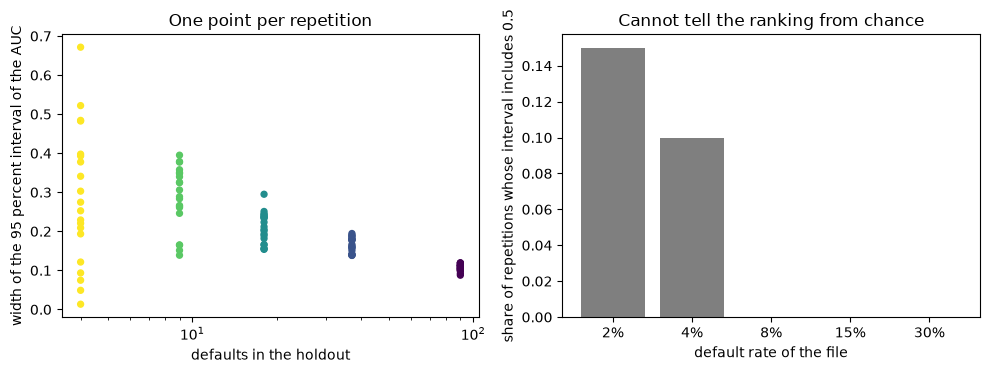

In [20]:
# Draw the AUC interval of every repetition against the defaults its holdout holds, and its share that includes chance
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.scatter(runs["holdout defaults"], runs["auc interval"], c=-np.log10(runs["prevalence"]), cmap="viridis", s=18)
left.set_xscale("log")
left.set_xlabel("defaults in the holdout")
left.set_ylabel("width of the 95 percent interval of the AUC")
left.set_title("One point per repetition")
right.bar([f"{p:.0%}" for p in by_prevalence.index], by_prevalence["share_with_chance"], color="tab:gray")
right.set_xlabel("default rate of the file")
right.set_ylabel("share of repetitions whose interval includes 0.5")
right.set_title("Cannot tell the ranking from chance")
fig.tight_layout()
plt.show()

On the left each point is one repetition, the width of its AUC interval against the defaults of its holdout on a logarithmic axis, coloured by prevalence. The width is read against the defaults, the quantity the interval depends on, and not against the prevalence. On the right the bars give the share of repetitions whose interval includes 0.5: 0, 0, 0, 0.10 and 0.15 from 30 down to 2 percent. The regime where the method fails is a holdout with fewer than about 10 defaults, where the interval is 0.26 to 0.30 wide and one repetition in ten, or more, cannot separate the AUC from chance. Between 10 and 20 defaults the AUC still works, but its interval is 0.2 wide or more. The figure shows the interval of the AUC only. The level tests depend on defaults too, and the next cell asks the engine how many a 95 percent level test needs in the holdout of each prevalence.

In [21]:
# The defaults a 95 percent level test needs in the holdout of each prevalence, set against the defaults expected there
power = []
for prevalence in prevalences:
    kept = len(good) + min(len(bad), int(round(prevalence / (1 - prevalence) * len(good))))
    holdout_size = int(round(0.3 * kept))
    needed = cal.critical_default_count(holdout_size, prevalence, q=0.95)
    expected = holdout_size * prevalence
    power.append({"prevalence": prevalence, "holdout records": holdout_size, "defaults expected": round(expected, 1),
                  "defaults needed to object": needed, "excess needed": round(needed / expected - 1, 2)})
pd.DataFrame(power)

,prevalence,holdout records,defaults expected,defaults needed to object,excess needed
0,0.30,300,90.0,104,0.16
1,0.15,247,37.0,47,0.27
2,0.08,228,18.2,26,0.43
3,0.04,219,8.8,15,0.71
4,0.02,214,4.3,9,1.10


The 30 percent row is the file as it is: 300 holdout records, 90 defaults expected, and a level test that objects only from 104, a 16 percent excess. At 15 percent the holdout has 247 records and the test needs 47 defaults where 37 are expected (27 percent more); at 8 percent it needs 26 where 18.2 are expected (43 percent); at 4 percent 15 where 8.8 (71 percent); at 2 percent 9 where 4.3, more than double (110 percent). A level test therefore loses its sensitivity in the same regime as the AUC: with fewer than about 10 expected defaults it can object only when the model understates the risk by more than half, which is what notebook 02 found with 50 cards. The table gives the sensitivity of the test and not the quality of any model. It says that a green light from the 2 percent file is nearly silent, because the holdout would need more than twice its expected defaults before the light moved.

### Using it on your own data

The chain above takes a file, and you will bring yours. Four things must be in place, in order. The source must be in the registry with its class and the cases that may read it. The file must be fetched, so that its hash is pinned in the manifest. A reader must map the publisher's layout to a contract 1 family, `scored_sample` for a PD model and `loan_panel` for lifetime models and the like, and the case must declare its extra fields. Then the call is `ingest.ingest(case_id, source_id, file_name, reader, data_root=..., family=..., extra_fields=...)`, followed by `split.stratified_split` and `evaluate.battery` as above. The next cell declares a source of your own twice, once as `derived-only` and once as `link-only`, and asks the registry whether a case C99 may read it.

In [22]:
# Declare a source of your own twice, as derived-only and as link-only, and ask the registry whether a case may read it
def declared(klass):
    return registry.Source(
        id="my-bank-file", name="My bank's scored extract", publisher="my bank", landing="https://example.org/",
        licence="Internal use under the bank's data agreement", klass=klass, access="manual", cases=("C99",),
        unverified=(),
    )


replies = []
for klass in ("derived-only", "link-only"):
    book = {**sources, "my-bank-file": declared(klass)}
    try:
        registry.assert_case_inputs("C99", ["my-bank-file"], registry=book)
        replies.append({"class": klass, "answer": "may read it"})
    except registry.LicenceError as refusal:
        replies.append({"class": klass, "answer": str(refusal)})
pd.DataFrame(replies)

,class,answer
0,derived-only,may read it
1,link-only,C99: my-bank-file is link-only; it may be link...


A source declared `derived-only` for case C99 may be read, and one declared `link-only` is refused with the wording of step 1: my-bank-file is link-only, it may be linked and never read. The class is the decision, and it comes from the licence you hold, not from the convenience of the project. A bank's own extract is typically `derived-only`: the case may read it and publish what it derives, and the rows stay private. The cell builds the entry in memory with the dataclass `registry.Source`. To make it real you add the same fields to `data-pipeline/config/sources.json`, where `registry.load` checks them: a licence fragment of at least eight characters, a landing page and the cases. The next cell builds the lineage of a document derived from that source.

In [23]:
# Build the lineage of a document derived from that source: it is refused until the file is fetched and its hash pinned
book = {**sources, "my-bank-file": declared("derived-only")}
mine = lineage.build(
    "C99", sources=["my-bank-file"], truth_status="real-outcomes", seed=1, code_version="0.0.0", reg=book
)
try:
    lineage.assert_publishable(mine)
except registry.LicenceError as refusal:
    print("refused:", refusal)
print("parameters of the ingest call:", list(inspect.signature(ingest.ingest).parameters))

refused: C99: refused, the input my-bank-file is not in the licence manifest (fetch it with data-pipeline/fetch.py first, so its bytes are hashed and its licence recorded)
parameters of the ingest call: ['case_id', 'source_id', 'file_name', 'reader', 'data_root', 'family', 'extra_fields', 'extra_rules', 'params']


The document is refused: C99 is refused because the input my-bank-file is not in the licence manifest, and the message names the remedy, `data-pipeline/fetch.py`, so that the bytes are hashed and the licence recorded. The registry says the source may be read, and still the lineage cannot be published until the file has been fetched and its entry written. The last line lists the nine parameters of the ingest call: the case and the source, the file name, the reader, the data root, the family, the extra fields and rules and the dataset parameters. The reader is the part you write, a function from the path of the file to a list of dictionaries that contract 1 then parses by kind. Never make it clean the data: a repaired value is a number the validator did not see. The last cell collects the checks to make after a run.

In [24]:
# The checks to make after a run on a file of your own, read here from the committed German run and its sample
counts = report.counts()
checks = [
    ("hash of the file equals the pin", f"pinned {pinned['sha256'][:16]}", "True"),
    ("rows accepted by contract 1", f"{counts['accepted']} of {counts['input']} (the sample)",
     "all, or each rejection explained"),
    ("columns contract 1 ignored", ", ".join(report.ignored_columns) or "none", "only fields you chose not to use"),
    ("defaults in the holdout", summary["holdout"]["defaults"], "a few dozen at least; below 10 the AUC says little"),
    ("battery rows in the state error", sum(row["light"] == "error" for row in rows), "0"),
    ("battery rows not evaluated", sum(row["light"] == "not_evaluated" for row in rows), "only tests without cuts"),
]
pd.DataFrame(checks, columns=["check", "this run", "what you want"])

,check,this run,what you want
0,hash of the file equals the pin,pinned e12d9d5def6845c0,True
1,rows accepted by contract 1,50 of 50 (the sample),"all, or each rejection explained"
2,columns contract 1 ignored,none,only fields you chose not to use
3,defaults in the holdout,90,a few dozen at least; below 10 the AUC says li...
4,battery rows in the state error,0,0
5,battery rows not evaluated,4,only tests without cuts


The table is the list to fill after any run on a file of your own, here read from the committed German case. The hash line shows the pin to compare with, which begins `e12d9d5def6845c0`; contract 1 accepted 50 of 50 records of the sample and ignored no column; the holdout holds 90 defaults; no battery row is in the state `error`; four rows are not evaluated, the tests without cut points. Each line has a value that tells you to stop: a hash that differs, a rejected row you cannot explain, an ignored column you meant to use, fewer than about 10 defaults in the holdout (the sweep above), an error row, or a not-evaluated row for a test the policy should colour. The table cannot check whether the file is the right one for the question, which is the reader's judgement.

## Results

**Answer:** Each stage gives one guarantee and each can be read in a committed document. For the German case the registry lists `uci-german` for C01 and refuses it for C05, the manifest pins the file with the hash `e12d9d5def6845c0`, contract 1 accepts the 50 applicants of the committed sample, the stratified split puts 168, 42 and 90 defaults into 560, 140 and 300 records, as the committed split does, and the committed battery has 24 rows, 20 green and 4 not evaluated. The last guarantee loses its worth as the holdout loses defaults: with 9, the median interval of the AUC is 0.297 wide, against 0.108 with 90, and with 4 the relation between width and defaults no longer holds.

- **Licence.** The registry holds 58 sources, 41 of them readable, and the manifest pins each file by hash; the stage refuses a file whose digest differs from the pin and says how to fetch an absent one. The lineage built from them equals the provenance of the committed German twin, and the licences table covers the code.
- **Contract.** Contract 1 has eight families declared in committed documents. It accepted every record of the committed sample; it checks ranges and kinds and never units, as notebook 04 showed.
- **Split.** A stratified holdout keeps the default rate exactly, where a random one wanders with a standard deviation of 0.0441 at 10 percent held out.
- **Test row.** Every row has the 18 keys of the `test-result` contract, so a light can be read again under another policy; the committed scorecard has no amber row among 24, and the stage on 25 applicants gives the same AUC as a direct engine call.
- **Where it breaks.** The width of the AUC interval follows $c/\sqrt{d_h}$ with $c$ near 1 from 90 to 9 holdout defaults, and below about 10 it widens and becomes unstable. A level test needs 104 defaults in the 300-record holdout, 16 percent over the 90 expected, and 9 in the holdout of the 2 percent file, 110 percent over the 4.3 expected.
- **Your own data.** Register the source with the class your licence supports, fetch it so the hash is pinned, write a reader, and read the six checks of the last table before any p-value.

What this notebook does not do: it does not read the licensed German file or the Taiwan file, which needs a reader that the notebook environment does not pin; a reader who holds the licence reruns the commands of the Data section. It fits no model: the PDs are those of the committed scorecard, and the product's ladder is built by topic 02.

## Summary

- A case is four stages and four guarantees: the registry and the pinned hash say what may be read, contract 1 says which records enter, the stratified split keeps the holdout honest, and the evaluation stage returns rows of the `test-result` contract.
- The registry holds 58 sources by class and the manifest pins each file by SHA-256; the lineage of a document equals the registry class and the manifest hash, and a document with an unfetched or link-only input is refused.
- A stratified holdout fixes its default count; a random one has a standard deviation of 0.0624 to 0.0139 for holdouts of 5 to 50 percent, as the hypergeometric formula says.
- The committed scorecard has no amber among its 24 rows, and the tests without cut points return `not_evaluated`.
- The interval of the AUC follows $c/\sqrt{d_h}$ with $c$ near 1 down to 9 defaults in the holdout, and below about 10 it widens and becomes unstable.

**What to try next.** Thin the defaults to 12 percent and 6 percent and read the checklist again, then write a reader for a CSV of your own, register it in a copy of the registry and run the three calls of the own-data section. Continue with topic 02, which builds the models that this battery validates.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- NIST (2015), Secure Hash Standard (SHS), FIPS PUB 180-4. https://doi.org/10.6028/NIST.FIPS.180-4
- scikit-learn, `train_test_split`, the stratified split behind the stage. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- Creative Commons, Attribution 4.0 International, the licence of the German Credit data. https://creativecommons.org/licenses/by/4.0/
- Hypergeometric distribution, the variance of a draw without replacement. https://en.wikipedia.org/wiki/Hypergeometric_distribution
- riskvalidation 1.1.0, the engine release the notebooks pin. https://pypi.org/project/riskvalidation/1.1.0/
- This repository: `docs/contracts/catalog.md` (the contracts read here) and `docs/guides/02_validate-your-own-model.md`.